In [ ]:
# Forecast of products demand based on M5 dataset

In [4]:
from pandas import to_datetime
%load_ext autoreload
%autoreload 2

In [5]:
import pandas as pd
import numpy as np
from pathlib import Path
from catboost import CatBoostRegressor
from src.data.catboost_config import run_catboost_experiment
from src.data.evaluate_model import evaluate_model
import gc
from sklearn.metrics import mean_absolute_error, mean_squared_error
from src.data.split_data import split_data


from src.data.load_data import load_data, prepare_calendar
from src.data.build_features import build_features

from src.data.load_data import load_data, prepare_calendar

In [18]:
data_path = "../data/m5"


sales, calendar, prices = load_data(data_path)
calendar = prepare_calendar(calendar)

df = build_features(
    sales=sales,
    calendar=calendar,
    prices=prices,
)
# nonzero_days_14 — число дней с ненулевыми продажами за последние 14 дней.
# nonzero_rate_14 — доля дней с ненулевыми продажами.
# avg_positive_demand_14 — средний объём продаж в дни с положительным спросом.
# adi_14 — средний интервал между днями с ненулевыми продажами.
# demand_regime_14 — классификация спроса на intermittent, regular или unknown.
print(df.shape)
print(df.head())
print(df.columns)

(58327370, 51)
       item_id  dept_id cat_id store_id state_id    d  sales       date  \
0  FOODS_1_001  FOODS_1  FOODS     CA_1       CA  d_1      3 2011-01-29   
1  FOODS_1_001  FOODS_1  FOODS     CA_1       CA  d_2      0 2011-01-30   
2  FOODS_1_001  FOODS_1  FOODS     CA_1       CA  d_3      0 2011-01-31   
3  FOODS_1_001  FOODS_1  FOODS     CA_1       CA  d_4      1 2011-02-01   
4  FOODS_1_001  FOODS_1  FOODS     CA_1       CA  d_5      4 2011-02-02   

   wm_yr_wk  sell_price  ...  std_sales_28  cv_sales_28  \
0     11101         2.0  ...           NaN          NaN   
1     11101         2.0  ...           NaN          NaN   
2     11101         2.0  ...           NaN          NaN   
3     11101         2.0  ...           NaN          NaN   
4     11101         2.0  ...           NaN          NaN   

   avg_positive_demand_14 adi_14 demand_regime_14 price_lag_1 price_median_7  \
0                     NaN    NaN          unknown         NaN            NaN   
1                  

In [19]:
candidates = df[
    (df["history_days_28"] == 28) &
    (df["nonzero_days_28"] == 28) &
    (df["avg_sales_28"] >= 2) &
    (df["cv_sales_28"] <= 0.5)
].copy()

print(
    candidates[
        [
            "item_id", "store_id", "date", "sales",
            "avg_sales_28", "cv_sales_28",
            "nonzero_days_28"
        ]
    ].head(20)
)

           item_id store_id       date  sales  avg_sales_28  cv_sales_28  \
57830  FOODS_1_004     CA_1 2012-04-13     15     25.428571     0.488071   
57832  FOODS_1_004     CA_1 2012-04-15      8     23.321429     0.497327   
57853  FOODS_1_004     CA_1 2012-05-06      6     10.357143     0.414006   
57854  FOODS_1_004     CA_1 2012-05-07      8      9.857143     0.397938   
57855  FOODS_1_004     CA_1 2012-05-08      7      9.571429     0.391362   
57856  FOODS_1_004     CA_1 2012-05-09     11      9.571429     0.391362   
57857  FOODS_1_004     CA_1 2012-05-10      5      9.714286     0.382981   
57858  FOODS_1_004     CA_1 2012-05-11     13      9.428571     0.399384   
57859  FOODS_1_004     CA_1 2012-05-12     17      9.357143     0.392628   
57860  FOODS_1_004     CA_1 2012-05-13     12      9.607143     0.410865   
57861  FOODS_1_004     CA_1 2012-05-14      9      9.750000     0.406080   
57862  FOODS_1_004     CA_1 2012-05-15     15      9.857143     0.395054   
57863  FOODS

In [21]:
def find_all_price_changes(df, item_id):
    data = df[df['item_id'] == item_id].copy()
    data['date'] = pd.to_datetime(data['date'])

    # Цена меняется по неделям, поэтому оставляем одну запись на магазин и неделю
    weekly = (
        data.sort_values('date')
        .groupby(['store_id', 'wm_yr_wk'], as_index=False)
        .agg(
            date=('date', 'min'),
            sell_price=('sell_price', 'first')
        )
        .sort_values(['store_id', 'date'])
    )

    # Предыдущая цена в каждом магазине
    weekly['prev_price'] = (
        weekly.groupby('store_id')['sell_price'].shift(1)
    )

    # Оставляем только изменения цены
    changes = weekly[
        weekly['prev_price'].notna() &
        (weekly['sell_price'] != weekly['prev_price'])
    ].copy()

    changes['change_pct'] = (
        (changes['sell_price'] / changes['prev_price'] - 1) * 100
    ).round(2)

    changes['change_type'] = changes['change_pct'].apply(
        lambda x: 'Снижение' if x < 0 else 'Повышение'
    )

    return changes[
        ['store_id', 'date', 'prev_price', 'sell_price',
         'change_pct', 'change_type']
    ].sort_values(['date', 'store_id']).reset_index(drop=True)

In [22]:
changes = find_all_price_changes(df, 'FOODS_1_004')
print(changes.to_string(index=False))

store_id       date  prev_price  sell_price  change_pct change_type
    CA_1 2013-12-28        1.78        1.50      -15.73    Снижение
    CA_2 2013-12-28        1.78        1.50      -15.73    Снижение
    CA_3 2013-12-28        1.78        1.50      -15.73    Снижение
    CA_4 2013-12-28        1.78        1.50      -15.73    Снижение
    TX_1 2013-12-28        1.78        1.50      -15.73    Снижение
    TX_2 2013-12-28        1.78        1.50      -15.73    Снижение
    TX_3 2013-12-28        1.78        1.50      -15.73    Снижение
    WI_1 2013-12-28        1.78        1.50      -15.73    Снижение
    WI_2 2013-12-28        1.78        1.50      -15.73    Снижение
    WI_3 2014-01-04        1.78        1.50      -15.73    Снижение
    CA_1 2014-02-01        1.50        1.78       18.67   Повышение
    CA_2 2014-02-01        1.50        1.78       18.67   Повышение
    CA_3 2014-02-01        1.50        1.78       18.67   Повышение
    CA_4 2014-02-01        1.50        1.78     

## We finished with features taken into account. Starting to build seasonal naive baseline

In [37]:
df1 = df[(df['sales']>0)& (df['nonzero_days_14']>=14) & (df['rolling_mean_14']>2)].groupby(['item_id', 'date']).sell_price.agg([min, max]).reset_index()


In [42]:
df1['price_range'] = round(df1['max']/df1['min'],2)
df1 = df1[(df1['min']>0.05) & (df1['price_range']<2)].sort_values(by='price_range', ascending = False)
print(df1.head())

            item_id       date   min   max  price_range
579730  FOODS_3_746 2012-09-23  1.00  1.98         1.98
579729  FOODS_3_746 2012-09-22  1.00  1.98         1.98
604045  FOODS_3_787 2014-08-09  0.98  1.94         1.98
604047  FOODS_3_787 2014-08-11  0.98  1.94         1.98
604046  FOODS_3_787 2014-08-10  0.98  1.94         1.98


In [29]:
import pandas as pd
import matplotlib.pyplot as plt


def plot_item_stores(item_id, date, df):
    date = pd.to_datetime(date)

    start_date = date - pd.Timedelta(days=30)
    end_date = date + pd.Timedelta(days=30)

    data = df[
        (df['item_id'] == item_id) &
        (pd.to_datetime(df['date']) >= start_date) &
        (pd.to_datetime(df['date']) <= end_date)
    ].copy()

    if data.empty:
        print(f'Нет данных для {item_id} в периоде {start_date.date()} — {end_date.date()}')
        return

    data['date'] = pd.to_datetime(data['date'])
    data = data.sort_values('date')

    fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

    # 1. Sales by store
    for store_id, group in data.groupby('store_id'):
        axes[0].plot(
            group['date'],
            group['sales'],
            label=store_id,
            alpha=0.8
        )

    axes[0].axvline(date, color='red', linestyle='--', label='Selected date')
    axes[0].set_title(f'Sales by store — {item_id}')
    axes[0].set_ylabel('Sales')
    axes[0].legend(title='Store', bbox_to_anchor=(1.02, 1), loc='upper left')
    axes[0].grid(alpha=0.3)

    # 2. Sell price by store
    for store_id, group in data.groupby('store_id'):
        prices = (
            group[['date', 'sell_price']]
            .dropna(subset=['sell_price'])
            .drop_duplicates(subset=['date'])
            .sort_values('date')
        )

        axes[1].plot(
            prices['date'],
            prices['sell_price'],
            label=store_id,
            marker='.',
            alpha=0.8
        )

    axes[1].axvline(date, color='red', linestyle='--', label='Selected date')
    axes[1].set_title(f'Sell price by store — {item_id}')
    axes[1].set_xlabel('Date')
    axes[1].set_ylabel('Sell price')
    axes[1].legend(title='Store', bbox_to_anchor=(1.02, 1), loc='upper left')
    axes[1].grid(alpha=0.3)

    fig.suptitle(
        f'{item_id}: {start_date.date()} — {end_date.date()}',
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

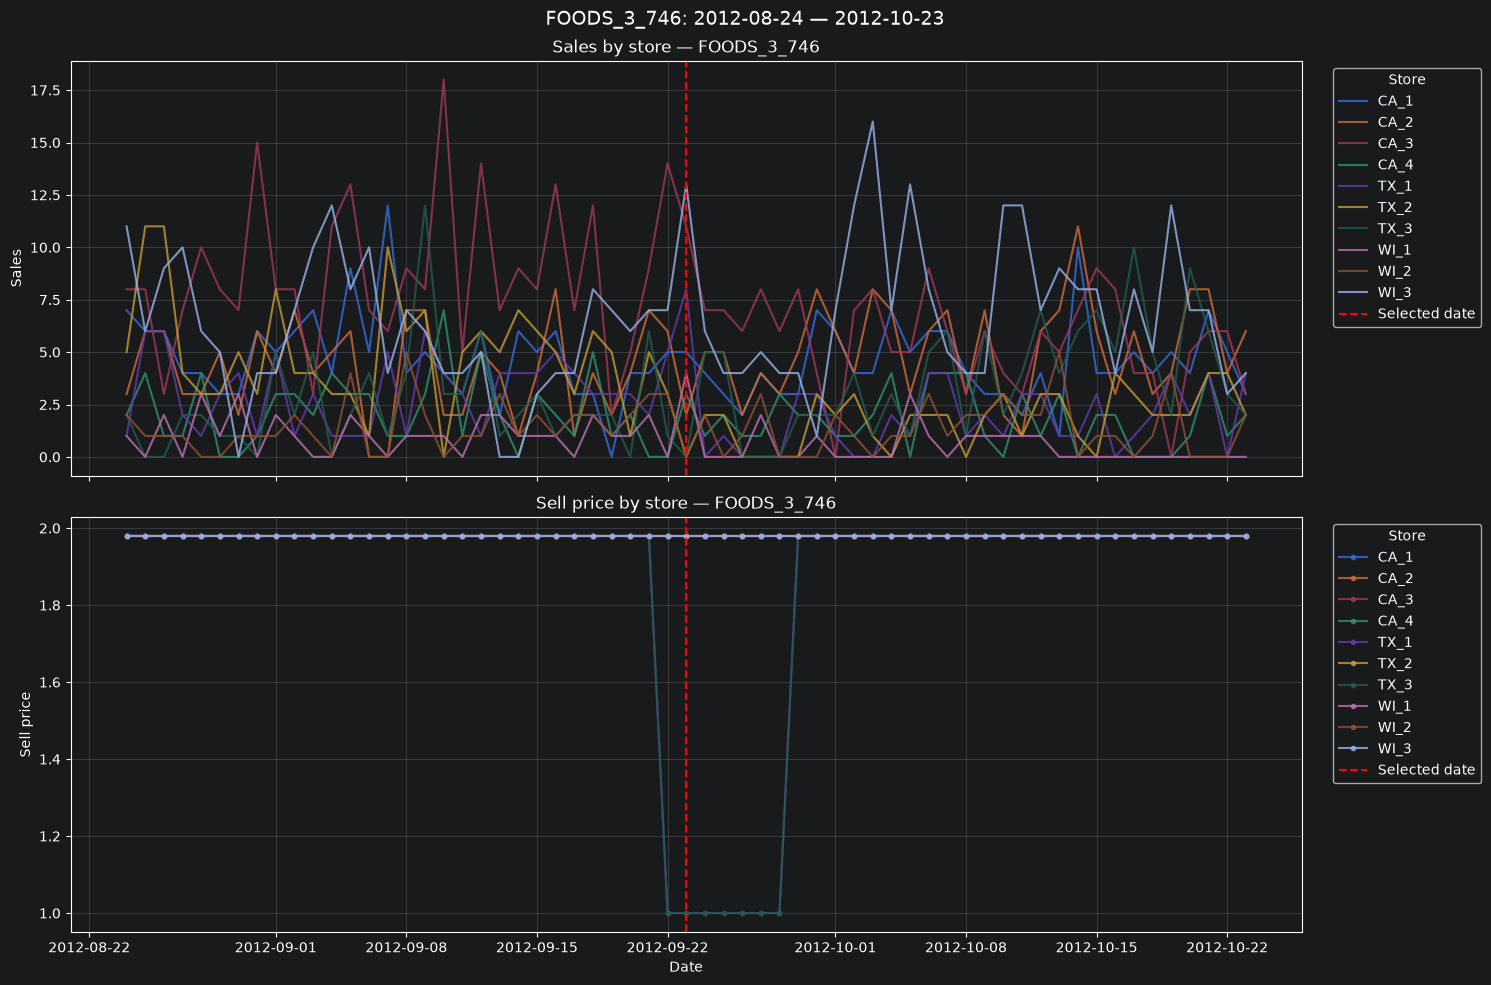

In [43]:
plot_item_stores(
    item_id='FOODS_1_004',
    date='2012-09-23',
    df=df
)

In [9]:
print(df[(df['item_id'] == 'FOODS_3_746') & (df['date']>pd.to_datetime('2012-09-23') -pd.Timedelta( days =5)) & (df['date']<pd.to_datetime('2012-09-23') +pd.Timedelta( days =5))].head(50))

              item_id  dept_id cat_id store_id state_id      d  sales  \
25921749  FOODS_3_746  FOODS_3  FOODS     CA_1       CA  d_600      0   
25921750  FOODS_3_746  FOODS_3  FOODS     CA_1       CA  d_601      4   
25921751  FOODS_3_746  FOODS_3  FOODS     CA_1       CA  d_602      4   
25921752  FOODS_3_746  FOODS_3  FOODS     CA_1       CA  d_603      5   
25921753  FOODS_3_746  FOODS_3  FOODS     CA_1       CA  d_604      5   
25921754  FOODS_3_746  FOODS_3  FOODS     CA_1       CA  d_605      4   
25921755  FOODS_3_746  FOODS_3  FOODS     CA_1       CA  d_606      3   
25921756  FOODS_3_746  FOODS_3  FOODS     CA_1       CA  d_607      2   
25921757  FOODS_3_746  FOODS_3  FOODS     CA_1       CA  d_608      4   
25923662  FOODS_3_746  FOODS_3  FOODS     CA_2       CA  d_600      2   
25923663  FOODS_3_746  FOODS_3  FOODS     CA_2       CA  d_601      4   
25923664  FOODS_3_746  FOODS_3  FOODS     CA_2       CA  d_602      7   
25923665  FOODS_3_746  FOODS_3  FOODS     CA_2     

store_id       date  prev_price  sell_price  change_pct change_type
    CA_1 2013-12-28        1.78        1.50      -15.73    Снижение
    CA_2 2013-12-28        1.78        1.50      -15.73    Снижение
    CA_3 2013-12-28        1.78        1.50      -15.73    Снижение
    CA_4 2013-12-28        1.78        1.50      -15.73    Снижение
    TX_1 2013-12-28        1.78        1.50      -15.73    Снижение
    TX_2 2013-12-28        1.78        1.50      -15.73    Снижение
    TX_3 2013-12-28        1.78        1.50      -15.73    Снижение
    WI_1 2013-12-28        1.78        1.50      -15.73    Снижение
    WI_2 2013-12-28        1.78        1.50      -15.73    Снижение
    WI_3 2014-01-04        1.78        1.50      -15.73    Снижение
    CA_1 2014-02-01        1.50        1.78       18.67   Повышение
    CA_2 2014-02-01        1.50        1.78       18.67   Повышение
    CA_3 2014-02-01        1.50        1.78       18.67   Повышение
    CA_4 2014-02-01        1.50        1.78     

In [15]:
import pandas as pd

item = 'FOODS_3_746'
event_start = pd.Timestamp('2012-09-22')
event_end = pd.Timestamp('2012-09-28')

data = df[
    (df['item_id'] == item) &
    df['date'].between(
        event_start - pd.Timedelta(weeks=4),
        event_end + pd.Timedelta(weeks=4)
    )
].copy()

data['period'] = 'before'
data.loc[data['date'].between(event_start, event_end), 'period'] = 'during'
data.loc[data['date'] > event_end, 'period'] = 'after'

summary = (
    data.groupby(['store_id', 'period'])
    .agg(
        avg_sales=('sales', 'mean'),
        total_sales=('sales', 'sum'),
        avg_price=('sell_price', 'mean'),
        days=('sales', 'size')
    )
    .reset_index()
)

summary.sort_values(['store_id', 'period'])

,store_id,period,avg_sales,total_sales,avg_price,days
0,CA_1,after,4.428571,124,1.98,28
1,CA_1,before,4.821429,135,1.98,28
2,CA_1,during,3.714286,26,1.98,7
3,CA_2,after,5.321429,149,1.98,28
4,CA_2,before,4.107143,115,1.98,28
5,CA_2,during,3.857143,27,1.98,7
6,CA_3,after,5.178571,145,1.98,28
7,CA_3,before,8.571429,240,1.98,28
8,CA_3,during,8.428571,59,1.98,7
9,CA_4,after,1.607143,45,1.98,28


In [16]:
# Магазины со скидкой
treated_stores = ['TX_1', 'TX_3']

# Преобразуем таблицу в удобный вид
sales_pivot = summary.pivot(
    index='store_id',
    columns='period',
    values='avg_sales'
)

# Среднее изменение продаж в магазинах со скидкой
treated_change = (
    sales_pivot.loc[treated_stores, 'during'] -
    sales_pivot.loc[treated_stores, 'before']
).mean()

# Контрольная группа: магазины без скидки
control_stores = [
    s for s in sales_pivot.index
    if s not in treated_stores
]

control_change = (
    sales_pivot.loc[control_stores, 'during'] -
    sales_pivot.loc[control_stores, 'before']
).mean()

did_effect = treated_change - control_change

print(f'Изменение продаж в treated: {treated_change:.3f}')
print(f'Изменение продаж в control: {control_change:.3f}')
print(f'DiD effect: {did_effect:.3f} единиц в день')


Изменение продаж в treated: -1.054
Изменение продаж в control: -0.763
DiD effect: -0.290 единиц в день


In [17]:
item = 'FOODS_3_746'
event_start = pd.Timestamp('2012-09-22')
event_end = pd.Timestamp('2012-09-28')

data = df[
    (df['item_id'] == item) &
    (df['store_id'].isin(['TX_1', 'TX_3', 'TX_2'])) &
    df['date'].between(
        event_start - pd.Timedelta(days=28),
        event_end + pd.Timedelta(days=14)
    )
].copy()

data['period'] = 'before'
data.loc[data['date'].between(event_start, event_end), 'period'] = 'during'
data.loc[data['date'] > event_end, 'period'] = 'after'

stockout_check = (
    data.groupby(['store_id', 'period'])
    .agg(
        days=('sales', 'size'),
        zero_sales_days=('sales', lambda x: (x == 0).sum()),
        zero_sales_rate=('sales', lambda x: (x == 0).mean()),
        avg_sales=('sales', 'mean'),
        avg_price=('sell_price', 'mean')
    )
    .reset_index()
)

stockout_check

,store_id,period,days,zero_sales_days,zero_sales_rate,avg_sales,avg_price
0,TX_1,after,14,2,0.142857,2.000000,1.98
1,TX_1,before,28,0,0.000000,3.107143,1.98
2,TX_1,during,7,4,0.571429,2.000000,1.00
3,TX_2,after,14,3,0.214286,1.714286,1.98
4,TX_2,before,28,1,0.035714,5.000000,1.98
5,TX_2,during,7,4,0.571429,1.000000,1.98
6,TX_3,after,14,0,0.000000,3.285714,1.98
7,TX_3,before,28,5,0.178571,2.571429,1.98
8,TX_3,during,7,4,0.571429,1.571429,1.00
